<a href="https://colab.research.google.com/github/itspratigya/query-by-image-vos-and-tracking/blob/pratigya_week1_env_setup/notebooks/query_by_image_vos_tracking_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Query-by-Image Video Object Search and Tracking: Task 1 setup

**Before running:** Runtime -> Change runtime type -> Hardware accelerator -> **T4 GPU** -> Save.

## Task 1: Set up DINOv2, FFmpeg/frame sampling, and SAM candidate generation


### Step 1.1: Environment Setup

In [1]:
!nvidia-smi

import sys, torch

print("python:", sys.version.split()[0])
print("torch :", torch.__version__, "| cuda available:", torch.cuda.is_available())

Tue Nov  3 06:55:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [25]:
import os, subprocess

SAM2_DIR   = "/content/sam2"
CKPT_DIR   = f"{SAM2_DIR}/checkpoints"
DRIVE_ROOT = "/content/drive/MyDrive"
DRIVE_CKPT = f"{DRIVE_ROOT}/qbi/checkpoints"          # checkpoint copies kept on Drive so they are not re-downloaded
DAVIS      = f"{DRIVE_ROOT}/data/DAVIS"               # this is where DAVIS folder is on Drive
IMG_DIR  = f"{DAVIS}/JPEGImages/480p"
ANN_DIR  = f"{DAVIS}/Annotations/480p"
WORK       = "/content/work"                          # temporary files (lost when the session ends)
WORK_OUT = f"{WORK}/out"
OUT        = f"{DRIVE_ROOT}/out"
PAIR_DIR = f"{WORK_OUT}/pairs"                   # results you want to keep
os.makedirs(WORK, exist_ok=True)

In [3]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


### Step 1.2: Data Setup - DAVIS 2017
Setup Datasets locally and add only what's nneded for test in drive.

MOSE consists of real-world complex scenarios. We will prepare MOSE in later weeks.

Train-test split
- Training set: DAVIS train (60 videos)
- Testing set: DAVIS val (30 videos)
- MOSE will be added to both in later weeks.

Storage note
Datasets take a lot of space and Google Drive has only 15 GB free in total. We keep only the DAVIS and MOSE subsets needed on Drive.

In [4]:
# Use DAVIS from Drive.
print("DAVIS folder exists:", os.path.exists(DAVIS))
print("Contents:", os.listdir(DAVIS))
print(sorted(os.listdir(f"{DAVIS}/JPEGImages/480p"))[:5], "...")

DAVIS folder exists: True
Contents: ['Annotations', 'JPEGImages', 'ImageSets']
['bear'] ...


### Step 2.1: Download and install SAM 2.1

In [5]:
# get SAM 2 and install it
!git clone https://github.com/facebookresearch/sam2.git
%cd {SAM2_DIR}
!pip install -e . -q

Cloning into 'sam2'...
remote: Enumerating objects: 1107, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 1107 (delta 13), reused 7 (delta 7), pack-reused 1089 (from 2)
Receiving objects: 100% (1107/1107), 134.85 MiB | 19.98 MiB/s, done.
Resolving deltas: 100% (385/385), done.
/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done


### Step 2.2: SAM 2.1 checkpoints
Only `sam2.1_hiera_small.pt` (candidates) and `sam2.1_hiera_large.pt` (query image and tracking) are needed.

In [6]:
%cd {CKPT_DIR}

/content/sam2/checkpoints


In [7]:
!bash download_ckpts.sh

--2026-11-03 07:00:44--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 65.9.168.52, 65.9.168.81, 65.9.168.4, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|65.9.168.52|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 156008466 (149M) [application/vnd.snesdev-page-table]
Saving to: ‘sam2.1_hiera_tiny.pt’

sam2.1_hiera_tiny.p 100%[===================>] 148.78M   306MB/s    in 0.5s    

2026-11-03 07:00:45 (306 MB/s) - ‘sam2.1_hiera_tiny.pt’ saved [156008466/156008466]

--2026-11-03 07:00:45--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 65.9.168.52, 65.9.168.81, 65.9.168.4, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|65.9.168.52|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 184416285 (176M) [application/vnd.sn

In [8]:
!ls -lh

total 1.5G
-rwxr-xr-x 1 root root 2.6K Nov  3 06:56 download_ckpts.sh
-rw-r--r-- 1 root root 309M Sep 29  2024 sam2.1_hiera_base_plus.pt
-rw-r--r-- 1 root root 857M Sep 29  2024 sam2.1_hiera_large.pt
-rw-r--r-- 1 root root 176M Sep 29  2024 sam2.1_hiera_small.pt
-rw-r--r-- 1 root root 149M Sep 29  2024 sam2.1_hiera_tiny.pt


### Step 2.3: SAM candidate generation
The cell below defines the settings and helper functions.

In [9]:
%cd {SAM2_DIR}

/content/sam2


In [10]:
from sam2.build_sam import build_sam2
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator

checkpoint = f"{CKPT_DIR}/sam2.1_hiera_small.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_s.yaml"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU")

sam = build_sam2(model_cfg,
                 checkpoint,
                 device=device,
                 apply_postprocessing=False
)

print("SAM2 Automatic Mask generator loaded")

device: cuda | Tesla T4
SAM2 Automatic Mask generator loaded


In [11]:
POINTS_PER_BATCH = 32   # 62; lower to 32 or 16 if you get CUDA out-of-memory

def run_generator(img, n):
    gen = SAM2AutomaticMaskGenerator(sam, points_per_side=n, points_per_batch=POINTS_PER_BATCH)
    with torch.inference_mode():
        return gen.generate(img)

In [12]:
def mask_to_box(m):
    ys, xs = np.where(m)
    return None if len(xs) == 0 else [xs.min(), ys.min(), xs.max() + 1, ys.max() + 1]

def cand_boxes_xyxy(cands):
    return [[c["bbox"][0], c["bbox"][1], c["bbox"][0] + c["bbox"][2], c["bbox"][1] + c["bbox"][3]]
            for c in cands]          # SAM 2 boxes are x, y, width, height

In [13]:
import numpy as np, pandas as pd
from PIL import Image

def load_frame(video, frame):
    img = np.array(Image.open(f"{DAVIS}/JPEGImages/480p/{video}/{frame:05d}.jpg").convert("RGB"))
    ann = np.array(Image.open(f"{DAVIS}/Annotations/480p/{video}/{frame:05d}.png"))  # palette ids, do not convert
    gt = {}
    for oid in np.unique(ann):
        if oid == 0: continue
        m = ann == oid
        gt[int(oid)] = {"mask": m, "box": mask_to_box(m)}
    return img, gt

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw(img, cands, gt, title, path):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.imshow(img)
    ax.axis("off")

    for x1, y1, x2, y2 in cand_boxes_xyxy(cands):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="cyan", lw=0.8, alpha=0.8))

    for g in gt.values():
        x1, y1, x2, y2 = g["box"]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=3))

    ax.set_title(title)
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()

ground-truth objects in this frame: [1]

=== n=8 (64 prompts): 8 candidates


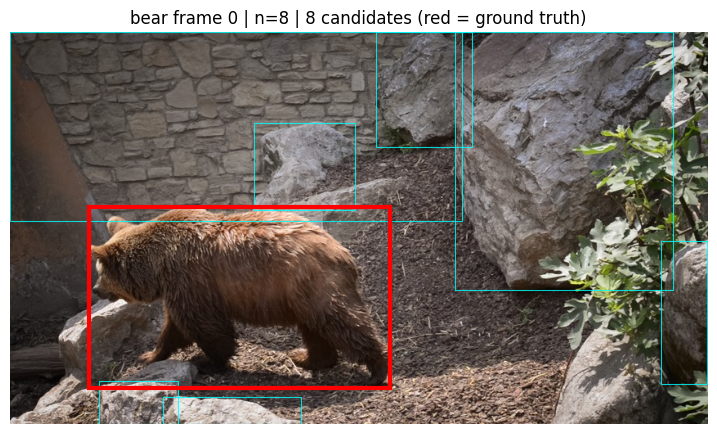


=== n=16 (256 prompts): 14 candidates


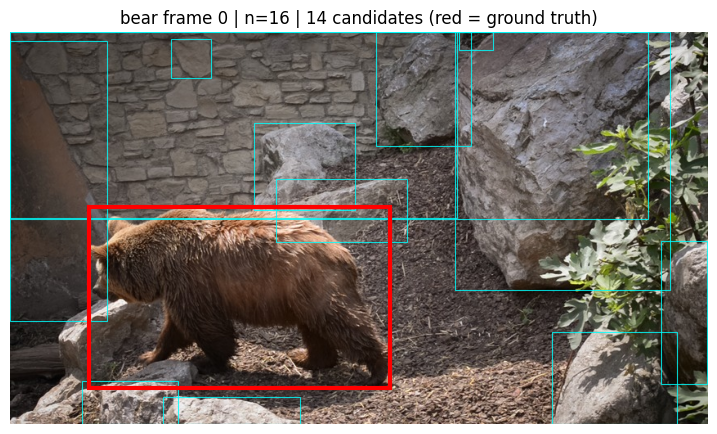


SUMMARY
 points_per_side  prompts  candidates
               8       64           8
              16      256          14


In [15]:
# Run n=8 and n=16 on one DAVIS frame and draw the boxes.

VIDEO = "bear"
FRAME = 0
GRIDS = [8, 16]         # points_per_side values to compare
IOU_THR = 0.5

os.makedirs(OUT, exist_ok=True)

img, gt = load_frame(VIDEO, FRAME)
print("ground-truth objects in this frame:", list(gt.keys()))

_ = run_generator(img, 4) #warm-up for CUDA start-up

summary = []
for n in GRIDS:
    cands = run_generator(img, n)
    summary.append({"points_per_side": n,
                    "prompts": n * n,
                    "candidates": len(cands)}
                   )
    print(f"\n=== n={n} ({n*n} prompts): {len(cands)} candidates")

    draw(img,
         cands,
         gt,
         f"{VIDEO} frame {FRAME} | n={n} | {len(cands)} candidates (red = ground truth)",
         f"{OUT}/{VIDEO}_f{FRAME}_n{n}.png"
         )

print("\nSUMMARY"); print(pd.DataFrame(summary).to_string(index=False))

------------------------------------------------------------------

------------------------------------------------------------------

### Step 3.1: DINOv2
DINOv2 loads through `torch.hub` and downloads its weights the first time (kept only for this session).

In [16]:
%cd /content

/content


In [17]:
device = "cuda" if torch.cuda.is_available() else "cpu"
dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vitb14").to(device).eval()
print("DINOv2 ViT-B/14 loaded on", device)

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth


100%|██████████| 330M/330M [00:01<00:00, 280MB/s]


DINOv2 ViT-B/14 loaded on cuda


### Step 4.1: FFmpeg
FFmpeg comes pre-installed in Colab.

In [18]:
!ffmpeg -version | head -n 1

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers


### Step 4.2: Try out FFmpeg
DAVIS and MOSE come as folders of JPEG frames, not video files, so FFmpeg is not needed for sampling initially. We  will use it later to build long videos for E7. Two commands to try now:

In [19]:
#1. Convert frames -> mp4 (assuming 24 fps)
!ffmpeg -framerate 24 -i {DAVIS}/JPEGImages/480p/bear/%05d.jpg -c:v libx264 -pix_fmt yuv420p {WORK}/bear.mp4 -y

#2. Convert mp4 -> 1 frame per second
!ffmpeg -i {WORK}/bear.mp4 -vf fps=1 {WORK}/%05d.jpg

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

To play the mp4 inside Colab, run this (it reads the file from WORK):

In [20]:
from IPython.display import HTML
from base64 import b64encode
mp4 = open(f"{WORK}/bear.mp4", "rb").read()
HTML('<video width=600 controls><source src="data:video/mp4;base64,' + b64encode(mp4).decode() + '" type="video/mp4"></video>')

### Step 5.1 : Query-image / Target pais
Settings and helper functions

Note- The execution of this part is painfully slow on colab mainly due to network latency, however these are very fast on local setup.

These codes are available under scripts directory for use in local env.

In [26]:
# Settings and helpers
import json
from tqdm.auto import tqdm

os.makedirs(f"{PAIR_DIR}/queries", exist_ok=True)

MIN_AREA   = 400    # ignore objects smaller than this many pixels
GAP_FRAMES = 12     # CHECK: targets start 12 frames (about 0.5 s) after the query frame

def load_img(video, i): return np.array(Image.open(f"{IMG_DIR}/{video}/{i:05d}.jpg").convert("RGB"))

def load_ann(video, i): return np.array(Image.open(f"{ANN_DIR}/{video}/{i:05d}.png"))    # pixel value = object id

def mask_to_box(m):
    ys, xs = np.where(m)
    return [int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1]          # x0, y0, x1, y1

def masked_crop(img, mask, box, margin=0.10, bg=127):
    """Crop the object (plus 10% margin) and paint everything outside its mask gray."""
    H, W = mask.shape
    x0, y0, x1, y1 = box
    w, h = x1 - x0, y1 - y0
    x0, y0 = int(max(0, x0 - margin * w)), int(max(0, y0 - margin * h))
    x1, y1 = int(min(W, x1 + margin * w)) + 1, int(min(H, y1 + margin * h)) + 1
    crop = img[y0:y1, x0:x1].copy()
    crop[~mask[y0:y1, x0:x1]] = bg
    return Image.fromarray(crop)

In [27]:
# Step Build the pairs and split them into dev / test
splits = {"dev":  open(f"{DAVIS}/ImageSets/2017/train.txt").read().split(),    # 60 videos
          "test": open(f"{DAVIS}/ImageSets/2017/val.txt").read().split()}      # 30 videos

def make_pairs(video, split):
    n = len(os.listdir(f"{IMG_DIR}/{video}"))
    anns = [load_ann(video, i) for i in range(n)]
    obj_ids = sorted({int(o) for a in anns for o in np.unique(a)} - {0, 255})   # 0 = background, 255 = void
    pairs, skipped = [], []
    for oid in obj_ids:
        boxes = {i: mask_to_box(a == oid) for i, a in enumerate(anns) if (a == oid).sum() >= MIN_AREA}
        if not boxes:
            skipped.append((video, oid, "too small")); continue
        q = min(boxes)                                          # query frame = first frame where the object is visible
        targets = {i: b for i, b in boxes.items() if i >= q + GAP_FRAMES}
        if not targets:
            skipped.append((video, oid, "not visible after the gap")); continue
        qpath = f"{PAIR_DIR}/queries/{video}__{oid}.jpg"
        masked_crop(load_img(video, q), anns[q] == oid, boxes[q]).save(qpath, quality=95)
        pairs.append({"pair_id": f"{video}__{oid}", "split": split, "video": video, "obj_id": oid,
                      "query_frame": q, "query_img": qpath, "query_box": boxes[q], "target_boxes": targets})
    return pairs, skipped

skipped_all = []
for split, videos in splits.items():
    pairs = []
    for v in tqdm(videos, desc=split):
        p, s = make_pairs(v, split)
        pairs += p; skipped_all += s
    with open(f"{PAIR_DIR}/pairs_{split}.jsonl", "w") as f:
        for r in pairs: f.write(json.dumps(r) + "\n")
    print(split, ":", len(pairs), "pairs from", len(videos), "videos")
print("skipped:", skipped_all)
# CHECK: this reads every annotation PNG from Drive, so it can take a few minutes.

dev:   0%|          | 0/10 [00:00<?, ?it/s]

dev : 18 pairs from 10 videos


test:   0%|          | 0/3 [00:00<?, ?it/s]

test : 5 pairs from 3 videos
skipped: []


dev: 18 | test: 5


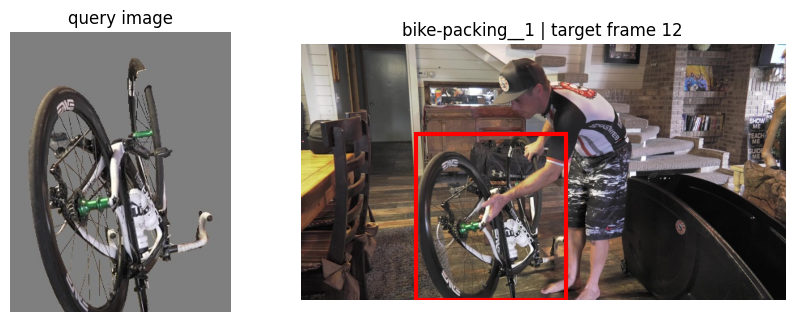

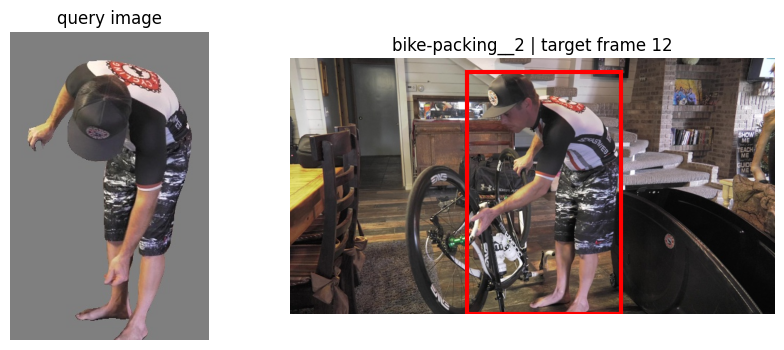

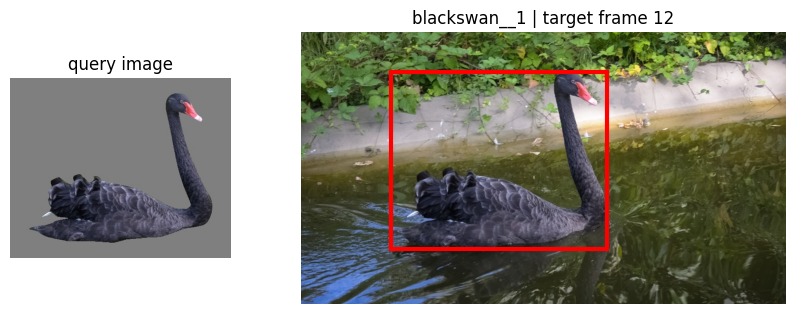

In [28]:
# Step Reload and check a few pairs by eye
def load_pairs(split):
    out = [json.loads(l) for l in open(f"{PAIR_DIR}/pairs_{split}.jsonl")]
    for r in out: r["target_boxes"] = {int(k): v for k, v in r["target_boxes"].items()}   # JSON turns int keys into strings
    return out

pairs_dev, pairs_test = load_pairs("dev"), load_pairs("test")
print("dev:", len(pairs_dev), "| test:", len(pairs_test))
assert not {p["video"] for p in pairs_dev} & {p["video"] for p in pairs_test}, "a video is in both splits!"

for p in pairs_test[::max(1, len(pairs_test) // 3)][:3]:
    f = min(p["target_boxes"]); x0, y0, x1, y1 = p["target_boxes"][f]
    fig, ax = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 2.2]})
    ax[0].imshow(Image.open(p["query_img"])); ax[0].set_title("query image"); ax[0].axis("off")
    ax[1].imshow(load_img(p["video"], f)); ax[1].axis("off")
    ax[1].add_patch(patches.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec="red", lw=3))
    ax[1].set_title(f"{p['pair_id']} | target frame {f}")
    plt.show()
# CHECK: does the query crop show the same object as the red box in the later frame?

### Step: 6.1 DINO embedding check

In [29]:
# Step Check that a query image turns into a DINOv2 embedding
import torch, torchvision.transforms as T

prep = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                  T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])    # ImageNet mean / std

def to_square(pil, bg=127):
    s = max(pil.size)                                                           # pad to a square so resizing does not squash the object
    canvas = Image.new("RGB", (s, s), (bg, bg, bg))
    canvas.paste(pil, ((s - pil.width) // 2, (s - pil.height) // 2))
    return canvas

@torch.no_grad()
def embed(pil):
    x = prep(to_square(pil)).unsqueeze(0).to(device)
    return torch.nn.functional.normalize(dino(x), dim=-1)[0].cpu().numpy()

p = pairs_test[0]
z = embed(Image.open(p["query_img"]))
print("shape:", z.shape, "| length:", round(float(np.linalg.norm(z)), 3), "  (expect (768,) and 1.0)")

# Same object in a later frame should be closer to the query than an object from another video
f = min(p["target_boxes"])
z_same  = embed(masked_crop(load_img(p["video"], f), load_ann(p["video"], f) == p["obj_id"], p["target_boxes"][f]))
other   = next(q for q in pairs_test if q["video"] != p["video"])
z_other = embed(Image.open(other["query_img"]))
print("cosine with same object later  :", round(float(z @ z_same), 3))
print("cosine with other video object :", round(float(z @ z_other), 3), "  (expect the first to be higher)")

shape: (768,) | length: 1.0   (expect (768,) and 1.0)
cosine with same object later  : 0.913
cosine with other video object : 0.121   (expect the first to be higher)
